<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3a_duais_algebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio III (a): a álgebra dos números duais

## Um infinitesimal que se anula ao quadrado: derivadas exatas, ângulos duais e o primeiro estado que dá a volta

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 3](X3_duais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3_duais.ipynb)) · **Próximo:** [X3b_duais_sistemas.ipynb](X3b_duais_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3b_duais_sistemas.ipynb))

**Objetivo.** Conhecer os **números duais** $a+\varepsilon b$, em que $\varepsilon$ é um símbolo com $\varepsilon\neq0$ e $\varepsilon^2=0$. Eles são a escolha $\alpha=0$ da família de produtos de ℝ² do notebook II(a), e servem para duas coisas muito diferentes, que esta série usa as duas:

- **derivar sem errar:** avaliar uma função num número dual devolve o valor **e a derivada exata**, sem `sympy` e sem diferenças finitas. É a **derivação automática** (modo direto), a mesma ideia que, no modo reverso, calcula os gradientes das redes neurais;
- **descrever um movimento de parafuso:** um giro de ângulo $\theta$ em torno de um eixo, junto com um deslizamento $d$ **ao longo do mesmo eixo**, é o **ângulo dual** $\hat\theta=\theta+\varepsilon d$. No domínio VII, os dual quaternions usam exatamente isso para descrever qualquer movimento rígido no espaço.

E aparece uma novidade que não tem nada a ver com $\varepsilon$: o ângulo $\theta$ vive num **círculo**. Depois de 360°, volta ao começo. É o primeiro estado da série que "dá a volta", e o $\boxplus$ e o $\boxminus$ deixam de ser uma soma e uma subtração simples.

**Roteiro**
1. Os números duais: operações, propriedades e o que se perde
2. Funções de números duais: a série de Taylor que para no primeiro termo
3. Derivação automática: uma classe `Dual` em Python
4. O ângulo dual: giro e deslizamento no mesmo eixo
5. O círculo: ângulos que dão a volta
6. A interface de domínio para o giro e deslizamento
7. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
import math, time
rng = np.random.default_rng(31)

---

## 1. Os números duais

Um número dual é $x=a+\varepsilon b$, com $a$ a **parte real** e $b$ a **parte dual**. As contas são as de polinômios em $\varepsilon$, jogando fora tudo o que tiver $\varepsilon^2$:

| operação | resultado |
|---|---|
| soma | $(a+\varepsilon b)+(c+\varepsilon d)=(a+c)+\varepsilon(b+d)$ |
| produto | $(a+\varepsilon b)(c+\varepsilon d)=ac+\varepsilon(ad+bc)$ |
| conjugado | $\overline{a+\varepsilon b}=a-\varepsilon b$, e $x\bar x=a^2$ |
| inverso | $(a+\varepsilon b)^{-1}=\dfrac1a-\varepsilon\dfrac{b}{a^2}$, **se $a\neq0$** |

**O que se perde.** Os duais formam um **anel comutativo**, mas não um corpo: os números com parte real zero, $\varepsilon b$, não têm inverso, e o produto de dois deles é zero: $(\varepsilon b)(\varepsilon d)=0$. Eles são **divisores de zero**. A regra "se $xy=0$, então $x=0$ ou $y=0$" falha.

**Uma representação por matrizes.** O dual $a+\varepsilon b$ se comporta exatamente como a matriz $\begin{bmatrix}a&b\\0&a\end{bmatrix}$: somar e multiplicar duais é somar e multiplicar essas matrizes, e $\varepsilon$ é a matriz $\begin{bmatrix}0&1\\0&0\end{bmatrix}$, cujo quadrado é zero. A representação permite conferir as propriedades com o `sympy` sem inventar nada: as leis valem porque valem para matrizes.

In [2]:
a, b, c_, d, e, f = sp.symbols("a b c d e f", real=True)
M = lambda a, b: sp.Matrix([[a, b], [0, a]])          # o dual a + εb como matriz
eps = M(0, 1)
print("ε² =", (eps * eps).tolist(), " ← zero, sem que ε seja zero")
x, y, z = M(a, b), M(c_, d), M(e, f)
print("produto:", (x * y).tolist(), " → (ac) + ε(ad + bc)")
for nome, expr in {"comutatividade": x * y - y * x,
                   "associatividade": (x * y) * z - x * (y * z),
                   "distributividade": x * (y + z) - (x * y + x * z)}.items():
    print(f"{nome:17s} → {sp.simplify(expr).tolist()}")
print("x · x̄ =", (x * M(a, -b)).tolist(), " → só a parte real ao quadrado")
print("inverso:", sp.simplify(x.inv()).tolist(), " → 1/a − ε b/a² (não existe se a = 0)")
print("(εb)(εd) =", (M(0, b) * M(0, d)).tolist(), " ← divisores de zero")

ε² = [[0, 0], [0, 0]]  ← zero, sem que ε seja zero
produto: [[a*c, a*d + b*c], [0, a*c]]  → (ac) + ε(ad + bc)
comutatividade    → [[0, 0], [0, 0]]
associatividade   → [[0, 0], [0, 0]]
distributividade  → [[0, 0], [0, 0]]
x · x̄ = [[a**2, 0], [0, a**2]]  → só a parte real ao quadrado
inverso: [[1/a, -b/a**2], [0, 1/a]]  → 1/a − ε b/a² (não existe se a = 0)
(εb)(εd) = [[0, 0], [0, 0]]  ← divisores de zero


---

## 2. Funções de números duais: a série de Taylor que para no primeiro termo

Como estender uma função $f$ (seno, exponencial, raiz quadrada) aos duais? Pela série de Taylor em torno da parte real:

$$f(a+\varepsilon b)=f(a)+f'(a)\,\varepsilon b+\frac{f''(a)}{2}\,\varepsilon^2b^2+\dots=f(a)+\varepsilon\,b\,f'(a),$$

porque todos os termos a partir do segundo têm $\varepsilon^2=0$. **A série para no primeiro termo, exatamente**, sem aproximação. Então:

$$\boxed{f(a+\varepsilon)=f(a)+\varepsilon f'(a)}$$

Avaliar $f$ em $a+\varepsilon$ dá, de uma vez, o **valor** e a **derivada** em $a$. A célula confere isso com o `sympy`: para cada função, expande em $\varepsilon$, joga fora $\varepsilon^2$ e compara a parte dual com a derivada simbólica.

In [3]:
t, ep = sp.symbols("t epsilon")
funcoes = {"exp": sp.exp(t), "sen": sp.sin(t), "1/(1+t²)": 1 / (1 + t**2), "√t": sp.sqrt(t), "exp(sen t)": sp.exp(sp.sin(t))}
for nome, fx in funcoes.items():
    serie = sp.series(fx.subs(t, t + ep), ep, 0, 2).removeO()        # até a primeira potência de ε
    parte_dual = sp.simplify(serie.coeff(ep, 1))
    print(f"{nome:11s} f(t+ε) = {sp.simplify(serie.coeff(ep, 0))} + ε·[{parte_dual}]   "
          f"parte dual − f'(t) = {sp.simplify(parte_dual - sp.diff(fx, t))}")
print("\na regra do produto aparece sozinha: (f + εf')(g + εg') =", sp.expand((sp.Symbol("f") + ep * sp.Symbol("f'")) * (sp.Symbol("g") + ep * sp.Symbol("g'"))).subs(ep**2, 0))

exp         f(t+ε) = exp(t) + ε·[exp(t)]   parte dual − f'(t) = 0


sen         f(t+ε) = sin(t) + ε·[cos(t)]   parte dual − f'(t) = 0
1/(1+t²)    f(t+ε) = 1/(t**2 + 1) + ε·[-2*t/(t**2 + 1)**2]   parte dual − f'(t) = 0
√t          f(t+ε) = sqrt(t) + ε·[1/(2*sqrt(t))]   parte dual − f'(t) = 0
exp(sen t)  f(t+ε) = exp(sin(t)) + ε·[exp(sin(t))*cos(t)]   parte dual − f'(t) = 0

a regra do produto aparece sozinha: (f + εf')(g + εg') = epsilon*f*g' + epsilon*f'*g + f*g


**A regra da cadeia também vem de graça.** Se $u=g(a+\varepsilon)=g(a)+\varepsilon g'(a)$, então $f(u)=f(g(a))+\varepsilon\,g'(a)f'(g(a))$: a parte dual é $(f\circ g)'(a)$. Por isso qualquer **programa** feito de somas, produtos e funções elementares, aplicado a um dual, devolve a derivada do programa inteiro. É isso que a próxima seção implementa.

---

## 3. Derivação automática: uma classe `Dual` em Python

Basta ensinar ao Python as regras da tabela da seção 1 e as funções elementares. A classe abaixo sobrecarrega os operadores (`+`, `-`, `*`, `/`, `**`) e define `sin`, `cos`, `exp`, `log`, `sqrt` e `atan2` para duais. As partes real e dual podem ser números ou vetores do NumPy.

In [4]:
class Dual:
    """Número dual re + ε·du, com ε² = 0. re e du podem ser floats ou arrays do NumPy."""
    __array_priority__ = 1000                     # para que  array * Dual  use as regras do Dual
    def __init__(self, re, du=0.0):
        self.re, self.du = re, du
    @staticmethod
    def _d(o): return o if isinstance(o, Dual) else Dual(o, 0.0)
    def __add__(self, o): o = Dual._d(o); return Dual(self.re + o.re, self.du + o.du)
    __radd__ = __add__
    def __neg__(self): return Dual(-self.re, -self.du)
    def __sub__(self, o): return self + (-Dual._d(o))
    def __rsub__(self, o): return Dual._d(o) - self
    def __mul__(self, o): o = Dual._d(o); return Dual(self.re * o.re, self.re * o.du + self.du * o.re)
    __rmul__ = __mul__
    def __truediv__(self, o): o = Dual._d(o); return Dual(self.re / o.re, (self.du * o.re - self.re * o.du) / o.re**2)
    def __rtruediv__(self, o): return Dual._d(o) / self
    def __pow__(self, n): return Dual(self.re**n, n * self.re**(n - 1) * self.du)       # n real (constante)
    def __repr__(self): return f"{self.re} + ε·{self.du}"
    # comparações olham só a parte real: permitem if/while dentro do programa derivado
    def __lt__(self, o): return self.re < Dual._d(o).re
    def __gt__(self, o): return self.re > Dual._d(o).re

def _eleva(f, df):
    """Estende f aos duais pela regra f(a + εb) = f(a) + ε b f'(a)."""
    return lambda x: Dual(f(x.re), df(x.re) * x.du) if isinstance(x, Dual) else f(x)
sin  = _eleva(np.sin, np.cos)
cos  = _eleva(np.cos, lambda a: -np.sin(a))
exp  = _eleva(np.exp, np.exp)
log  = _eleva(np.log, lambda a: 1 / a)
sqrt = _eleva(np.sqrt, lambda a: 0.5 / np.sqrt(a))
def atan2(y, x):
    y, x = Dual._d(y), Dual._d(x)
    return Dual(np.arctan2(y.re, x.re), (x.re * y.du - y.re * x.du) / (x.re**2 + y.re**2))

def derivada(f, x):
    """f'(x) por derivação automática: a parte dual de f(x + ε)."""
    return f(Dual(x, 1.0)).du

f = lambda x: exp(sin(x))
x0 = 1.0
exata = np.cos(x0) * np.exp(np.sin(x0))
print(f"f(1 + ε) = {f(Dual(x0, 1.0))}")
confere("derivada dual de exp(sen x) em x = 1", derivada(f, x0), exata, tol=2e-16, relativo=True)

f(1 + ε) = 2.319776824715853 + ε·1.253380767493447
OK   derivada dual de exp(sen x) em x = 1:  diferença relativa máxima = 0.00e+00


**O dilema do passo, resolvido.** No notebook I(a), as diferenças finitas tinham um dilema: passo grande dá erro de truncamento, passo pequeno dá cancelamento, e o melhor que se conseguia, com a diferença central, era um erro de uns $5\times10^{-12}$. A derivada dual não tem passo nenhum, e o seu erro é só o do arredondamento das contas: no máximo da ordem do épsilon de máquina, e neste exemplo, zero.

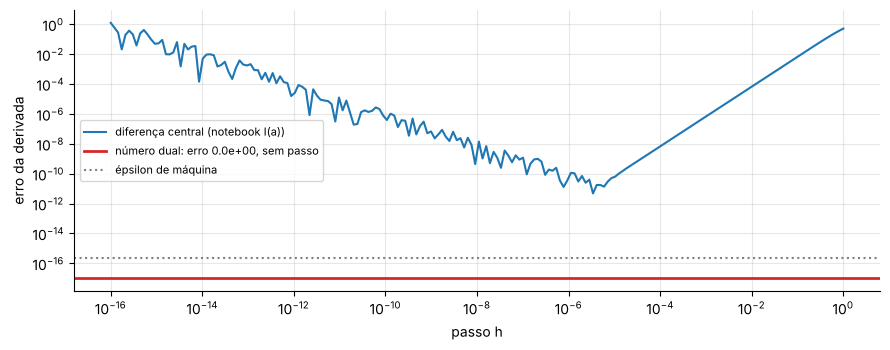

melhor diferença central: 4.8e-12;  número dual: 0.0e+00


In [5]:
fn = lambda x: np.exp(np.sin(x))
hs = np.logspace(-16, 0, 200)
e_central = np.abs((fn(x0 + hs) - fn(x0 - hs)) / (2 * hs) - exata)
e_dual = abs(derivada(f, x0) - exata)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.loglog(hs, e_central + 1e-18, label="diferença central (notebook I(a))")
ax.axhline(max(e_dual, 1e-17), color="tab:red", lw=2, label=f"número dual: erro {e_dual:.1e}, sem passo")
ax.axhline(np.finfo(float).eps, ls=":", color="gray", label="épsilon de máquina")
ax.set_xlabel("passo h"); ax.set_ylabel("erro da derivada"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"melhor diferença central: {e_central.min():.1e};  número dual: {e_dual:.1e}")

### Derivando um programa, não uma fórmula

A derivação automática não precisa de uma **fórmula**: ela deriva o que o programa **faz**, com laços e condições. O exemplo abaixo calcula $\sqrt{s}$ pelo método babilônico (Newton para $x^2=s$, notebook I(b)), parando quando duas iterações quase coincidem. Passando $s+\varepsilon$, a parte dual sai como a derivada do resultado em relação a $s$, que deve ser $1/(2\sqrt s)$. O programa não sabe que está sendo derivado.

E um vetor inteiro de pontos pode ser derivado de uma vez, com a parte real e a parte dual como arrays.

In [6]:
def raiz_babilonica(s, tol=1e-15):
    x = s * 0.5 + 0.5                       # chute inicial
    while True:
        novo = 0.5 * (x + s / x)
        if abs((novo - x).re if isinstance(novo, Dual) else novo - x) < tol * abs(novo.re if isinstance(novo, Dual) else novo):
            return novo
        x = novo

r = raiz_babilonica(Dual(2.0, 1.0))
print(f"raiz_babilonica(2 + ε) = {r}")
confere("valor = √2", r.re, math.sqrt(2), tol=1e-15)
confere("parte dual = 1/(2√2): o laço while foi derivado", r.du, 1 / (2 * math.sqrt(2)), tol=1e-15)

xs = np.linspace(0, 2 * np.pi, 9)
g = lambda x: sin(x) * exp(-x / 4) + x**2 / 10
gd = g(Dual(xs, np.ones_like(xs)))                           # nove derivadas numa passada
confere("derivada vetorizada = fórmula", gd.du, np.cos(xs) * np.exp(-xs / 4) - np.sin(xs) * np.exp(-xs / 4) / 4 + xs / 5, tol=1e-14)

raiz_babilonica(2 + ε) = 1.414213562373095 + ε·0.35355339059327373
OK   valor = √2:  diferença máxima = 2.22e-16
OK   parte dual = 1/(2√2): o laço while foi derivado:  diferença máxima = 0.00e+00
OK   derivada vetorizada = fórmula:  diferença máxima = 5.55e-17


**Modo direto e modo reverso.** Um dual carrega a derivada em relação a **uma** direção de entrada. Para o jacobiano de uma função de $n$ variáveis, o modo direto faz $n$ passadas, uma por coluna (o notebook III(b) faz isso). Quando há muitas entradas e uma saída só, como a perda de uma rede neural com milhões de pesos, o **modo reverso** (a retropropagação) é muito mais barato: uma passada para a frente, guardando as contas, e uma para trás. O `torch` e o `jax` fazem os dois; os números duais são a forma mais simples de entender o primeiro.

---

## 4. O ângulo dual: giro e deslizamento no mesmo eixo

Uma barra presa a um eixo por uma **junta cilíndrica** pode **girar** em torno do eixo (ângulo $\theta$) e **deslizar** ao longo dele (distância $d$). O par $(\theta,d)$ se escreve como um número dual, o **ângulo dual**:

$$\hat\theta=\theta+\varepsilon d .$$

Fazer um movimento depois do outro é somar os ângulos duais: os giros se somam, os deslizamentos se somam, e a ordem não importa. Até aqui, nada que um par de números não fizesse. O interessante é o que acontece com as **funções trigonométricas** de um ângulo dual:

$$\cos\hat\theta=\cos\theta-\varepsilon\,d\sin\theta,\qquad \sin\hat\theta=\sin\theta+\varepsilon\,d\cos\theta .$$

É a regra da seção 2, com $f'$ no lugar certo. E as **identidades** trigonométricas continuam valendo para ângulos duais. Este fato, o **princípio da transferência** (de Kotelnikov e Study, no século XIX), é o que permite, no domínio VII, pegar as fórmulas das rotações e transformá-las em fórmulas de movimentos de parafuso trocando $\theta$ por $\hat\theta$.

In [7]:
th, dd = sp.symbols("theta d", real=True)
def trig_dual(fx):
    """f(θ + εd) truncada em ε²: devolve (parte real, parte dual)."""
    s = sp.series(fx.subs(t, th + ep * dd), ep, 0, 2).removeO()
    return sp.simplify(s.coeff(ep, 0)), sp.simplify(s.coeff(ep, 1))
cr, cd = trig_dual(sp.cos(t)); sr, sd = trig_dual(sp.sin(t))
print(f"cos(θ + εd) = {cr} + ε·({cd})");  print(f"sen(θ + εd) = {sr} + ε·({sd})")
# cos² + sen² para o ângulo dual, jogando fora ε²
soma = sp.expand((cr + ep * cd)**2 + (sr + ep * sd)**2).subs(ep**2, 0)
print("cos²θ̂ + sen²θ̂ =", sp.simplify(soma), "  ← a identidade sobrevive")
t1, t2, d1, d2 = sp.symbols("theta1 theta2 d1 d2", real=True)
lado_esq = sp.series(sp.cos(t).subs(t, t1 + t2 + ep * (d1 + d2)), ep, 0, 2).removeO()
c1 = sp.series(sp.cos(t).subs(t, t1 + ep * d1), ep, 0, 2).removeO(); s1 = sp.series(sp.sin(t).subs(t, t1 + ep * d1), ep, 0, 2).removeO()
c2 = sp.series(sp.cos(t).subs(t, t2 + ep * d2), ep, 0, 2).removeO(); s2 = sp.series(sp.sin(t).subs(t, t2 + ep * d2), ep, 0, 2).removeO()
lado_dir = sp.expand(c1 * c2 - s1 * s2).subs(ep**2, 0)
print("cos(θ̂1 + θ̂2) − (cos θ̂1 cos θ̂2 − sen θ̂1 sen θ̂2) =", sp.simplify(sp.expand(lado_esq - lado_dir)))

# a mesma conta com a classe Dual, numericamente
A_, B_ = Dual(0.7, 0.3), Dual(-1.9, 1.2)
confere("cos(Â + B̂) = cos Â cos B̂ − sen Â sen B̂ (parte real e dual)",
        [cos(A_ + B_).re, cos(A_ + B_).du],
        [(cos(A_) * cos(B_) - sin(A_) * sin(B_)).re, (cos(A_) * cos(B_) - sin(A_) * sin(B_)).du], tol=1e-15)

cos(θ + εd) = cos(theta) + ε·(-d*sin(theta))
sen(θ + εd) = sin(theta) + ε·(d*cos(theta))
cos²θ̂ + sen²θ̂ = 1   ← a identidade sobrevive


cos(θ̂1 + θ̂2) − (cos θ̂1 cos θ̂2 − sen θ̂1 sen θ̂2) = 0
OK   cos(Â + B̂) = cos Â cos B̂ − sen Â sen B̂ (parte real e dual):  diferença máxima = 5.55e-17


---

## 5. O círculo: ângulos que dão a volta

O deslizamento $d$ é um número real como os do domínio I. O giro $\theta$ não: $\theta$ e $\theta+2\pi$ são a **mesma** posição da barra. O conjunto dos ângulos é um **círculo**, e não uma reta. Três consequências práticas, que reaparecem em todos os domínios com rotação:

1. **Guardar o ângulo num intervalo fixo**, por convenção $(-\pi,\pi]$. A função que faz isso é o "enrolamento", $\mathrm{wrap}(\theta)$. Uma forma robusta é $\mathrm{atan2}(\sin\theta,\cos\theta)$; outra, mais rápida, usa o resto da divisão por $2\pi$.
2. **A diferença entre dois ângulos** tem de ser enrolada: de 170° para −170° a barra girou 20°, e não −340°. Isso é o $\boxminus$ deste domínio: $\theta_2\boxminus\theta_1=\mathrm{wrap}(\theta_2-\theta_1)$.
3. **A média de ângulos** não é a média dos números: a média de 170° e −170° é 180°, e não 0°. A média certa é a **média circular**: a direção da média dos vetores unitários $(\cos\theta_i,\sin\theta_i)$.

In [8]:
def wrap(a):
    """Enrola um ângulo para (−π, π]."""
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

graus = np.radians
for a_ in [3.0, 3.2, -3.2, 7.0, -np.pi, np.pi, 100.0]:
    print(f"wrap({a_:8.4f}) = {wrap(a_):8.4f}   atan2(sen, cos) = {np.arctan2(np.sin(a_), np.cos(a_)):8.4f}")
A = rng.uniform(-50, 50, 1000)
confere("wrap = atan2(sen, cos) em 1000 ângulos sorteados", wrap(A), np.arctan2(np.sin(A), np.cos(A)), tol=1e-13)
confere("wrap(π) = π (o intervalo é (−π, π])", wrap(np.pi), np.pi, tol=0)

print(f"\nde 170° para −170°: diferença ingênua {np.degrees(graus(-170) - graus(170)):.0f}°;  enrolada {np.degrees(wrap(graus(-170) - graus(170))):.0f}°")
ang = graus(np.array([170.0, -170.0, 175.0, -165.0]))
media_ingenua = np.degrees(ang.mean())
media_circular = np.degrees(np.arctan2(np.sin(ang).mean(), np.cos(ang).mean()))
print(f"ângulos {np.degrees(ang)}: média ingênua {media_ingenua:.1f}°;  média circular {media_circular:.1f}°")
confere("média circular de 170°, −170°, 175°, −165° = −177,5° (isto é, 182,5°)", media_circular, -177.5, tol=0.05)

wrap(  3.0000) =   3.0000   atan2(sen, cos) =   3.0000
wrap(  3.2000) =  -3.0832   atan2(sen, cos) =  -3.0832
wrap( -3.2000) =   3.0832   atan2(sen, cos) =   3.0832
wrap(  7.0000) =   0.7168   atan2(sen, cos) =   0.7168
wrap( -3.1416) =   3.1416   atan2(sen, cos) =  -3.1416
wrap(  3.1416) =   3.1416   atan2(sen, cos) =   3.1416
wrap(100.0000) =  -0.5310   atan2(sen, cos) =  -0.5310
OK   wrap = atan2(sen, cos) em 1000 ângulos sorteados:  diferença máxima = 5.55e-15
OK   wrap(π) = π (o intervalo é (−π, π]):  diferença máxima = 0.00e+00

de 170° para −170°: diferença ingênua -340°;  enrolada 20°
ângulos [ 170. -170.  175. -165.]: média ingênua 2.5°;  média circular -177.5°
OK   média circular de 170°, −170°, 175°, −165° = −177,5° (isto é, 182,5°):  diferença máxima = 0.00e+00


**Leitura.** A média ingênua dá 2,5°, do lado **oposto** do círculo: um filtro que fizesse isso com as partículas de um ângulo (notebook II(d)) mandaria o perseguidor olhar para trás. A média circular dá −177,5°, isto é, 182,5°: os quatro ângulos estão em torno de 180°, um pouco mais para o lado de 190° e 195°. Aqui ela coincide com a média aritmética de 170°, 190°, 175° e 195° (os mesmos ângulos, escritos sem enrolar); em geral, as duas só ficam próximas quando os ângulos estão próximos uns dos outros.

**O $\varepsilon$ e o círculo não se misturam.** Repare que o problema do círculo é do giro $\theta$, e não do infinitesimal $\varepsilon$: a parte dual $d$ é um real comum. No ângulo dual $\hat\theta=\theta+\varepsilon d$, só a parte real é enrolada.

---

## 6. A interface de domínio para o giro e deslizamento

O grupo de movimentos deste domínio é o dos giros e deslizamentos em torno de **um** eixo fixo: $SO(2)\times\mathbb R$, o produto do círculo pela reta. O estado é o ângulo dual $\hat\theta=\theta+\varepsilon d$, com $\theta\in(-\pi,\pi]$.

| operação | significado | no ângulo dual |
|---|---|---|
| `compoe(g, h)` | girar e deslizar, depois girar e deslizar de novo | $\mathrm{wrap}(\theta_g+\theta_h)+\varepsilon(d_g+d_h)$ |
| `inverso(g)` | desfazer | $\mathrm{wrap}(-\theta_g)-\varepsilon d_g$ |
| `identidade` | ficar parado | $0+\varepsilon0$ |
| `Exp(ξ)` | o movimento com velocidade $\xi=(\omega,v)$ por uma unidade de tempo | $\mathrm{wrap}(\omega)+\varepsilon v$ |
| `Log(g)` | a velocidade constante "mais curta" que produz $g$ | $(\theta_g,d_g)$, com $\theta_g\in(-\pi,\pi]$ |

**A primeira vez que `Exp` não é invertível.** Girar a $\omega=4$ rad/s por um segundo leva ao mesmo lugar que girar a $4-2\pi\approx-2{,}28$ rad/s. A `Log` escolhe a velocidade de menor módulo; então $\mathrm{Log}(\mathrm{Exp}(\xi))=\xi$ só vale para $|\omega|<\pi$. Isso não é um defeito do código: é a geometria do círculo, e vai valer, com outras palavras, para as rotações de todos os domínios seguintes. Os testes usam incrementos pequenos, que é como o filtro de Kalman os usa.

In [9]:
class DominioCilindrico:
    """Domínio III: giro θ e deslizamento d em torno de um eixo fixo. Estado: o ângulo dual θ + εd (θ enrolado)."""
    nome = "SO(2)×ℝ (ângulo dual)"
    dim = 2
    identidade = Dual(0.0, 0.0)
    def compoe(self, g, h): return Dual(float(wrap(g.re + h.re)), g.du + h.du)
    def inverso(self, g):   return Dual(float(wrap(-g.re)), -g.du)
    def Exp(self, xi):      return Dual(float(wrap(xi[0])), float(xi[1]))
    def Log(self, g):       return np.array([g.re, g.du])
    def mais(self, x, d):   return self.compoe(x, self.Exp(d))
    def menos(self, y, x):  return self.Log(self.compoe(self.inverso(x), y))

def testa_dominio(D, amostra, tol=1e-12):
    """Os mesmos testes dos domínios I e II."""
    g, h, k = amostra(), amostra(), amostra()
    print(f"domínio {D.nome}")
    confere("  associatividade da composição", D.menos(D.compoe(D.compoe(g, h), k), D.compoe(g, D.compoe(h, k))), 0, tol)
    confere("  identidade", D.menos(D.compoe(g, D.identidade), g), 0, tol)
    confere("  inverso", D.menos(D.compoe(g, D.inverso(g)), D.identidade), 0, tol)
    d = D.Log(amostra()) * 0.3
    confere("  Log(Exp(δ)) = δ", D.Log(D.Exp(d)), d, tol)
    confere("  (x ⊞ δ) ⊟ x = δ", D.menos(D.mais(g, d), g), d, tol)
    confere("  x ⊞ (y ⊟ x) = y", D.menos(D.mais(g, D.menos(h, g)), h), 0, tol)

Dc = DominioCilindrico()
amostra = lambda: Dual(float(rng.uniform(-np.pi, np.pi)), float(rng.normal(scale=2)))
testa_dominio(Dc, amostra)

g = Dual(3.0, 0.5); h = Dual(0.4, -0.2)
print("\n3,0 rad + 0,4 rad =", Dc.compoe(g, h).re, " (enrolado: passou de π e voltou para perto de −π)")
confere("compor comuta (o grupo é abeliano)", Dc.menos(Dc.compoe(g, h), Dc.compoe(h, g)), 0, tol=1e-15)
xi = np.array([4.0, 1.0])
print("Log(Exp((4, 1))) =", Dc.Log(Dc.Exp(xi)), " ← o giro de 4 rad virou 4 − 2π: Exp não é invertível no círculo todo")
confere("Log(Exp(ξ)) = ξ com o giro trocado por 4 − 2π", Dc.Log(Dc.Exp(xi)), [4 - 2 * np.pi, 1.0], tol=1e-15)

domínio SO(2)×ℝ (ângulo dual)
OK     associatividade da composição:  diferença máxima = 8.88e-16
OK     identidade:  diferença máxima = 0.00e+00
OK     inverso:  diferença máxima = 0.00e+00
OK     Log(Exp(δ)) = δ:  diferença máxima = 1.67e-16
OK     (x ⊞ δ) ⊟ x = δ:  diferença máxima = 1.67e-16
OK     x ⊞ (y ⊟ x) = y:  diferença máxima = 4.44e-16

3,0 rad + 0,4 rad = -2.883185307179586  (enrolado: passou de π e voltou para perto de −π)
OK   compor comuta (o grupo é abeliano):  diferença máxima = 0.00e+00
Log(Exp((4, 1))) = [-2.283185  1.      ]  ← o giro de 4 rad virou 4 − 2π: Exp não é invertível no círculo todo
OK   Log(Exp(ξ)) = ξ com o giro trocado por 4 − 2π:  diferença máxima = 0.00e+00


**Para pensar.** O grupo $SO(2)\times\mathbb R$ é comutativo, como os dos domínios I e II. A diferença está na **forma** do conjunto: o giro vive num círculo, e o deslizamento numa reta, de modo que o estado vive num **cilindro**. Um cilindro é localmente igual ao plano (perto de qualquer ponto, $\boxplus$ é uma soma), mas globalmente diferente: andando sempre na mesma direção do giro, volta-se ao começo. Esta é a ideia de **variedade**, que os domínios VI a VIII levarão às rotações do espaço. Os notebooks (c) e (d) deste domínio mostram o que acontece quando um integrador ou um filtro de Kalman esquece que o ângulo dá a volta.

---

## 7. Exercícios

1. **Segunda derivada.** Um "dual de duais", $(a+\varepsilon_1b)+\varepsilon_2(c+\varepsilon_1d)$, com $\varepsilon_1^2=\varepsilon_2^2=0$ mas $\varepsilon_1\varepsilon_2\neq0$, carrega a segunda derivada no coeficiente de $\varepsilon_1\varepsilon_2$ (são os números **hiperduais**). Implemente com `Dual(Dual(...), Dual(...))` e confira a segunda derivada de $e^{\sin x}$. Compare com os **números tridentes** do domínio VIII, em que também $\varepsilon_1\varepsilon_2=0$: o que eles deixam de carregar?
2. **Mais funções.** Acrescente `tan`, `arctan` e `abs` à classe `Dual`. O que fazer com `abs` em $a=0$, onde a derivada não existe? E com `if x > 0`?
3. **Gradiente pelo modo direto.** Escreva `gradiente(f, x)` para $f:\mathbb R^n\to\mathbb R$, com $n$ passadas de duais. Meça o tempo para $f(\mathbf x)=\sum_i\sin(x_i)x_{i+1}$ com $n=10,100,1000$. Como cresce? Por que o modo reverso seria melhor aqui?
4. **Divisores de zero na prática.** Calcule `Dual(0.0, 1.0) / Dual(0.0, 1.0)` com a classe. O que acontece, e por que o resultado é razoável ou não?
5. **Média circular ponderada.** Escreva a média circular com pesos $w_i$ e use-a para estimar a direção de uma nuvem de partículas num círculo. Quando o comprimento do vetor médio é pequeno (perto de zero), o que isso diz sobre a nuvem?